In [1]:
import pandas as pd

# 1. Load the dataset
df = pd.read_csv('house_price_prediction_dataset.csv')

# 2. Display basic information about the dataset
print("--- Initial Dataset Info ---")
print(f"Shape of dataset: {df.shape}")
print(df.info())

# 3. Check for missing values
print("\n--- Missing Values Per Column ---")
print(df.isnull().sum())

--- Initial Dataset Info ---
Shape of dataset: (125, 9)
<class 'pandas.DataFrame'>
RangeIndex: 125 entries, 0 to 124
Data columns (total 9 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   House_ID                 125 non-null    int64  
 1   Area_m2                  123 non-null    float64
 2   Bedrooms                 124 non-null    float64
 3   Bathrooms                124 non-null    float64
 4   House_Age_Years          124 non-null    float64
 5   Distance_to_City_km      124 non-null    float64
 6   Parking_Spaces           124 non-null    float64
 7   Neighborhood             124 non-null    str    
 8   House_Price_Million_RWF  124 non-null    float64
dtypes: float64(7), int64(1), str(1)
memory usage: 9.8 KB
None

--- Missing Values Per Column ---
House_ID                   0
Area_m2                    2
Bedrooms                   1
Bathrooms                  1
House_Age_Years            1
Distance_to_Ci

In [2]:
# Drop 'House_ID' as it's just an identifier and not a feature
if 'House_ID' in df.columns:
    df = df.drop(columns=['House_ID'])
    print("Dropped 'House_ID' column.")

Dropped 'House_ID' column.


In [3]:
# Check initial number of duplicates
initial_duplicates = df.duplicated().sum()
print(f"Number of duplicate rows found: {initial_duplicates}")

# Drop duplicate rows and reset the index
df = df.drop_duplicates().reset_index(drop=True)
print(f"Dataset shape after removing duplicates: {df.shape}")

Number of duplicate rows found: 5
Dataset shape after removing duplicates: (120, 8)


In [4]:
# 1. Fill missing numerical values with the median of each respective column
numerical_cols = [
    'Area_m2',
    'Bedrooms',
    'Bathrooms',
    'House_Age_Years',
    'Distance_to_City_km',
    'Parking_Spaces',
    'House_Price_Million_RWF'
]

for col in numerical_cols:
    if col in df.columns:
        median_val = df[col].median()
        df[col] = df[col].fillna(median_val)
        print(f"Filled missing values in '{col}' with median: {median_val}")

# 2. Fill missing categorical values with the mode (most frequent category)
if 'Neighborhood' in df.columns:
    mode_neighborhood = df['Neighborhood'].mode()[0]
    df['Neighborhood'] = df['Neighborhood'].fillna(mode_neighborhood)
    print(f"Filled missing values in 'Neighborhood' with mode: {mode_neighborhood}")

Filled missing values in 'Area_m2' with median: 107.9
Filled missing values in 'Bedrooms' with median: 3.0
Filled missing values in 'Bathrooms' with median: 3.0
Filled missing values in 'House_Age_Years' with median: 6.8
Filled missing values in 'Distance_to_City_km' with median: 3.45
Filled missing values in 'Parking_Spaces' with median: 1.0
Filled missing values in 'House_Price_Million_RWF' with median: 152.9
Filled missing values in 'Neighborhood' with mode: Musanze


In [5]:
# Function to cap outliers using the IQR method
def cap_outliers(data, column):
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    # Cap the values between lower and upper bound
    data[column] = data[column].clip(lower=lower_bound, upper=upper_bound)
    print(f"Capped outliers in '{column}' between {lower_bound:.2f} and {upper_bound:.2f}")

# Apply outlier capping to key numerical columns
for col in ['Area_m2', 'House_Price_Million_RWF']:
    if col in df.columns:
        cap_outliers(df, col)

Capped outliers in 'Area_m2' between -3.74 and 224.96
Capped outliers in 'House_Price_Million_RWF' between 22.05 and 285.45


In [6]:
# Perform One-Hot Encoding on 'Neighborhood'
if 'Neighborhood' in df.columns:
    df = pd.get_dummies(df, columns=['Neighborhood'], drop_first=True, dtype=int)
    print("Applied One-Hot Encoding to 'Neighborhood'.")

Applied One-Hot Encoding to 'Neighborhood'.


In [7]:
# Save the cleaned dataset to a new CSV file
output_file = 'cleaned_house_price_dataset.csv'
df.to_csv(output_file, index=False)
print(f"\nData cleaning complete! Cleaned dataset saved as '{output_file}'.")
print(f"Final cleaned dataset shape: {df.shape}")


Data cleaning complete! Cleaned dataset saved as 'cleaned_house_price_dataset.csv'.
Final cleaned dataset shape: (120, 12)


In [8]:
import pandas as pd
from sklearn.model_selection import train_test_split

# 1. Load your cleaned dataset
df = pd.read_csv('cleaned_house_price_dataset.csv')

# 2. Define features (X) and target (y)
# 'House_Price_Million_RWF' is our target variable
target_column = 'House_Price_Million_RWF'

X = df.drop(columns=[target_column])
y = df[target_column]

print(f"Features shape (X): {X.shape}")
print(f"Target shape (y): {y.shape}")

Features shape (X): (120, 11)
Target shape (y): (120,)


In [9]:
# Split data: 80% for training, 20% for testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Training set size: {X_train.shape[0]} rows")
print(f"Testing set size: {X_test.shape[0]} rows")

Training set size: 96 rows
Testing set size: 24 rows


In [10]:
from sklearn.preprocessing import StandardScaler

# Initialize the scaler
scaler = StandardScaler()

# Fit on training data and transform both training and testing data
# (Only scale numerical columns if you have one-hot encoded binary columns)
numerical_cols = [
    'Area_m2', 'Bedrooms', 'Bathrooms', 
    'House_Age_Years', 'Distance_to_City_km', 'Parking_Spaces'
]

X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[numerical_cols] = scaler.fit_transform(X_train[numerical_cols])
X_test_scaled[numerical_cols] = scaler.transform(X_test[numerical_cols])

print("Features scaled successfully.")

Features scaled successfully.


In [11]:
from sklearn.ensemble import RandomForestRegressor

# Initialize the model
model = RandomForestRegressor(n_estimators=100, random_state=42)

# Train (fit) the model on the training data
model.fit(X_train_scaled, y_train)

print("Model training completed!")

Model training completed!


In [12]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Make predictions on the test set
y_pred = model.predict(X_test_scaled)

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("--- Model Evaluation Metrics ---")
print(f"Mean Absolute Error (MAE): {mae:.2f} Million RWF")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f} Million RWF")
print(f"R-squared (R2 Score): {r2:.4f}")

--- Model Evaluation Metrics ---
Mean Absolute Error (MAE): 30.05 Million RWF
Root Mean Squared Error (RMSE): 38.33 Million RWF
R-squared (R2 Score): 0.5276


In [13]:
import joblib

# Save the model and scaler to disk
joblib.dump(model, 'house_price_model.pkl')
joblib.dump(scaler, 'feature_scaler.pkl')

print("Model and scaler saved successfully as 'house_price_model.pkl' and 'feature_scaler.pkl'!")

Model and scaler saved successfully as 'house_price_model.pkl' and 'feature_scaler.pkl'!


In [14]:
# 1. Load the saved model and scaler
loaded_model = joblib.load('house_price_model.pkl')
loaded_scaler = joblib.load('feature_scaler.pkl')

# 2. Prepare new house data (must match the exact columns of X_train)
# Example feature dictionary matching your dataset columns
new_house_data = pd.DataFrame([{
    'Area_m2': 150.0,
    'Bedrooms': 3.0,
    'Bathrooms': 2.0,
    'House_Age_Years': 5.0,
    'Distance_to_City_km': 4.5,
    'Parking_Spaces': 2.0,
    'Neighborhood_Kigali City': 1, # Depending on how one-hot encoding structured columns
    'Neighborhood_Musanze': 0,
    'Neighborhood_Nyarugenge': 0,
    # ... include all other one-hot encoded columns present in X
}])

# Ensure columns align with training features
new_house_data = new_house_data.reindex(columns=X.columns, fill_value=0)

# Scale numerical columns
new_house_data[numerical_cols] = loaded_scaler.transform(new_house_data[numerical_cols])

# 3. Predict price
predicted_price = loaded_model.predict(new_house_data)
print(f"\nPredicted House Price: {predicted_price[0]:.2f} Million RWF")


Predicted House Price: 185.44 Million RWF


In [15]:
from sklearn.model_selection import GridSearchCV

# Define the parameter grid to search
param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10]
}

# Initialize Grid Search
grid_search = GridSearchCV(
    estimator=RandomForestRegressor(random_state=42),
    param_grid=param_grid,
    cv=5, # 5-fold cross-validation
    scoring='r2',
    n_jobs=-1
)

# Fit to training data
grid_search.fit(X_train_scaled, y_train)

print(f"Best Hyperparameters: {grid_search.best_params_}")
print(f"Best Cross-Validation R2 Score: {grid_search.best_score_:.4f}")

Best Hyperparameters: {'max_depth': None, 'min_samples_split': 5, 'n_estimators': 200}
Best Cross-Validation R2 Score: 0.4482


Matplotlib is building the font cache; this may take a moment.


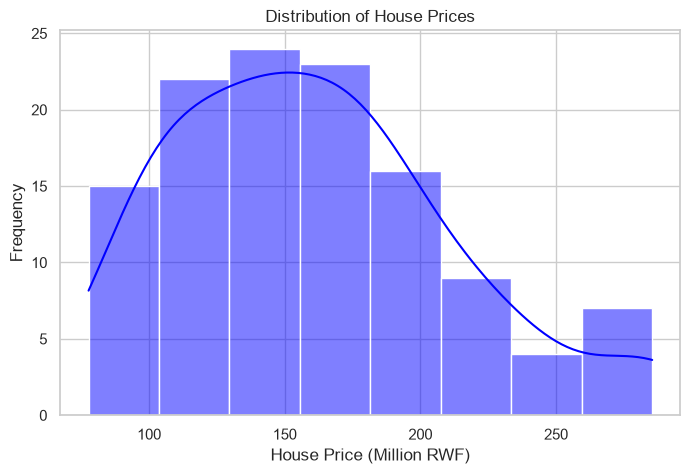

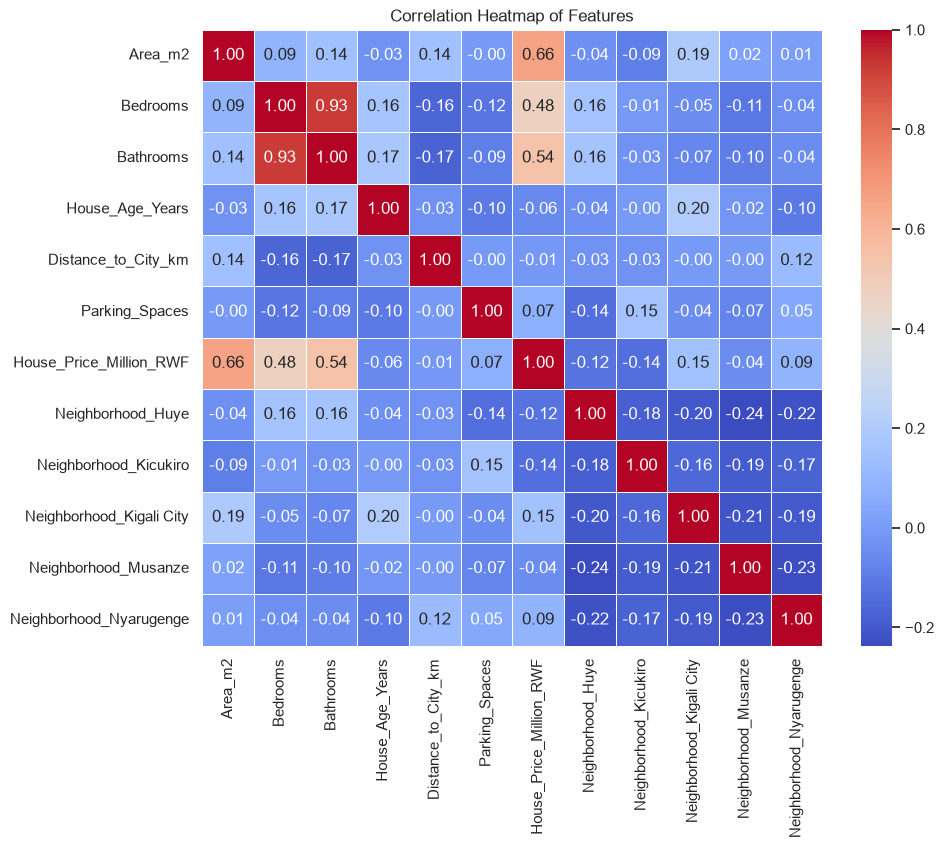

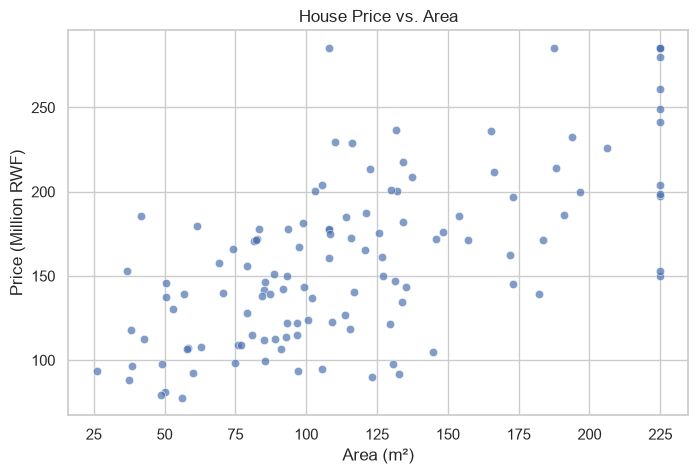

In [16]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load data
df = pd.read_csv('cleaned_house_price_dataset.csv')

# Set style
sns.set_theme(style="whitegrid")

# 1. Distribution of House Prices
plt.figure(figsize=(8, 5))
sns.histplot(df['House_Price_Million_RWF'], kde=True, color='blue')
plt.title('Distribution of House Prices')
plt.xlabel('House Price (Million RWF)')
plt.ylabel('Frequency')
plt.show()

# 2. Correlation Heatmap
plt.figure(figsize=(10, 8))
numeric_df = df.select_dtypes(include=['number'])
sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Correlation Heatmap of Features')
plt.show()

# 3. Area vs. House Price Scatter Plot
plt.figure(figsize=(8, 5))
sns.scatterplot(x='Area_m2', y='House_Price_Million_RWF', data=df, alpha=0.7)
plt.title('House Price vs. Area')
plt.xlabel('Area (m²)')
plt.ylabel('Price (Million RWF)')
plt.show()

In [18]:
import joblib
# Save the column names used during training
joblib.dump(X.columns.tolist(), 'model_features.pkl')

['model_features.pkl']